In [1]:
import numpy as np
import xarray as xr
import pandas as pd
import cartopy.crs as ccrs
import cartopy.feature as cf
import matplotlib.pyplot as plt
from netCDF4 import Dataset 
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
from scipy import stats
from scipy import signal
from cartopy.io.shapereader import Reader
import regionmask
import geopandas as gpd
from shapely.geometry import Point
from shapely.geometry import Polygon
from shapely.ops import unary_union
import matplotlib.patches as mpatches


In [2]:
ds1=xr.open_dataset('monthly_ind1901-2022_rfp25.nc')
ds1

<xarray.Dataset>
Dimensions:    (TIME: 1464, bnds: 2, LONGITUDE: 135, LATITUDE: 129)
Coordinates:
  * TIME       (TIME) datetime64[ns] 1901-01-16 ... 2022-12-16
  * LONGITUDE  (LONGITUDE) float64 66.5 66.75 67.0 67.25 ... 99.5 99.75 100.0
  * LATITUDE   (LATITUDE) float64 6.5 6.75 7.0 7.25 ... 37.75 38.0 38.25 38.5
Dimensions without coordinates: bnds
Data variables:
    TIME_bnds  (TIME, bnds) datetime64[ns] ...
    RAINFALL   (TIME, LATITUDE, LONGITUDE) float64 ...
Attributes:
    CDI:          Climate Data Interface version 1.9.7.1 (http://mpimet.mpg.d...
    Conventions:  CF-1.6
    history:      Tue Jun 20 11:41:22 2023: cdo monsum ind1901-2022_rfp25.nc ...
    frequency:    mon
    CDO:          Climate Data Operators version 1.9.7.1 (http://mpimet.mpg.d...

In [3]:
# --- Define 'lons','lats' variables
lons = ds1['LONGITUDE'][:]  
lats = ds1['LATITUDE'][:] 
# --- select JJAS months
fname='Homogeneous Region Shape File1 (1)/Homogeneous Region Shape File1.shp'
rf = ds1['RAINFALL'].sel(TIME=np.in1d(ds1['TIME.month'], [6, 7, 8, 9]))
rf

<xarray.DataArray 'RAINFALL' (TIME: 488, LATITUDE: 129, LONGITUDE: 135)>
[8498520 values with dtype=float64]
Coordinates:
  * TIME       (TIME) datetime64[ns] 1901-06-15T12:00:00 ... 2022-09-15T12:00:00
  * LONGITUDE  (LONGITUDE) float64 66.5 66.75 67.0 67.25 ... 99.5 99.75 100.0
  * LATITUDE   (LATITUDE) float64 6.5 6.75 7.0 7.25 ... 37.75 38.0 38.25 38.5
Attributes:
    long_name:  Rainfall
    units:      mm
    history:    From ind1901_rfp25.grd

In [4]:
#Prepare JJAS 1951-2022 
r=rf[200:488,:,:]
r

<xarray.DataArray 'RAINFALL' (TIME: 288, LATITUDE: 129, LONGITUDE: 135)>
[5015520 values with dtype=float64]
Coordinates:
  * TIME       (TIME) datetime64[ns] 1951-06-15T12:00:00 ... 2022-09-15T12:00:00
  * LONGITUDE  (LONGITUDE) float64 66.5 66.75 67.0 67.25 ... 99.5 99.75 100.0
  * LATITUDE   (LATITUDE) float64 6.5 6.75 7.0 7.25 ... 37.75 38.0 38.25 38.5
Attributes:
    long_name:  Rainfall
    units:      mm
    history:    From ind1901_rfp25.grd

In [5]:
r_jun=r.sel(TIME=np.in1d(r['TIME.month'], [6]))
r_JUN=r_jun.to_numpy()
print(r_JUN.shape)

r_jul=r.sel(TIME=np.in1d(r['TIME.month'], [7]))
r_jul
r_JUL=r_jul.to_numpy()
print(r_JUL.shape)

r_aug=r.sel(TIME=np.in1d(r['TIME.month'], [8]))
r_aug
r_AUG=r_aug.to_numpy()
print(r_AUG.shape)

r_sep=r.sel(TIME=np.in1d(r['TIME.month'], [9]))
r_sep
r_SEP=r_sep.to_numpy()
r_SEP
print(r_SEP.shape)

(72, 129, 135)
(72, 129, 135)
(72, 129, 135)
(72, 129, 135)


In [6]:
r_JJAS=r_JUN+r_JUL+r_AUG+r_SEP
RCLIM=np.nanmean(r_JJAS,axis=0)
print(RCLIM.shape)

(129, 135)


C:\Users\CMPG-PC\AppData\Local\Temp\ipykernel_17100\2973988334.py:2: RuntimeWarning: Mean of empty slice
  RCLIM=np.nanmean(r_JJAS,axis=0)


In [7]:
lon=ds1['LONGITUDE'][:].values
lat=ds1['LATITUDE'][:].values

In [8]:
df = gpd.read_file(fname)
df
#mask = regionmask.mask_geopandas(df, lons, lats)
#nw = np.where(mask ==0, 1, np.nan)
# central = np.where(mask==1, 1, np.nan)
# east = np.where(mask==2,1, np.nan)
# south = np.where(mask==3,1,np.nan)
# plt.pcolormesh(south)

,objectid,object_id,name,area_sqkm,state_code,region_cod,subdivisio,actual_rf,normal_rf,departure,...,normal_r_2,departur_2,country_4,area_sqm_2,category_3,uorder_4,name_lbl_4,st_area__3,st_lengt_3,geometry
0,1,10.0,UTTARAKHAND,53484.28459,UTTARAKHAND,NORTH WEST INDIA,UTTARAKHAND,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"POLYGON ((72.29700 24.62463, 72.28979 24.61920..."
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((86.78302 20.35724, 86.78259 20..."
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((96.16260 29.38080, 96.16864 29..."
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,INDIA,2835.54534,NaN,1,A AND N ISLANDS,0.60593,46.42105,"MULTIPOLYGON (((93.90344 7.08002, 93.90320 7.0..."


In [9]:
#mask = regionmask.mask_geopandas(df, lon, lat)

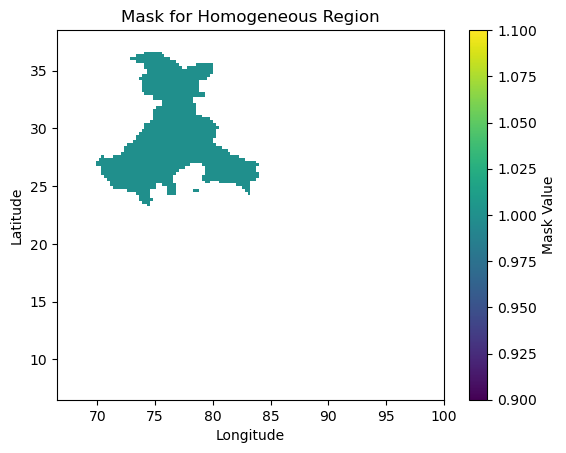

In [10]:
# Choose the index of the homogeneous region you want to mask
region_index = 0

# Get the geometry of the selected region
nw_geometry = df['geometry'][region_index]

# Create a shapely Polygon object from the geometry
nw_polygon = Polygon(nw_geometry)

# Create a 2D mask array with NaN values
mask_nw = np.full((len(lat), len(lon)), np.nan)

# Iterate over each grid point
for i in range(len(lon)):
    for j in range(len(lat)):
        # Check if the grid point falls within the region
        if nw_polygon.contains(Point(lon[i], lat[j])):
            mask_nw[j, i] = 1  # Inside the region

# Plot the mask
plt.imshow(mask_nw, extent=[lon.min(), lon.max(), lat.min(), lat.max()], origin='lower')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Mask for Homogeneous Region')
plt.colorbar(label='Mask Value')
plt.show()

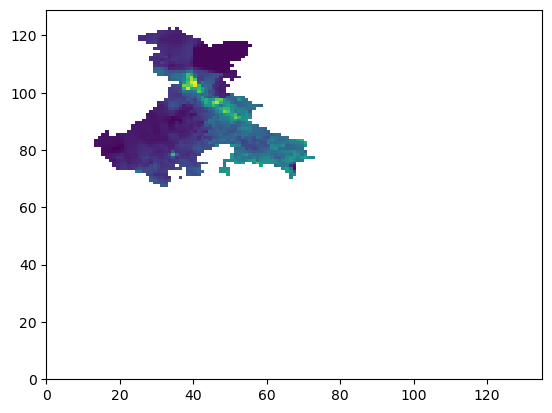

In [11]:
rf_nw=r_JJAS*mask_nw
plt.pcolormesh(rf_nw[0,:,:])

In [12]:
r_nw= np.nanmean(rf_nw, axis =(1,2))
r_nw

array([381.96674986, 546.83015547, 616.27001881, 561.60102112,
       637.5846391 , 604.50405159, 556.21268782, 635.19608854,
       546.71653438, 535.25495306, 633.56337144, 693.05698826,
       506.84479579, 598.94242492, 368.75642059, 474.36214183,
       582.59580641, 437.03890346, 490.76185189, 558.7367609 ,
       600.71882972, 378.10278125, 577.63933031, 418.24338102,
       715.91837096, 585.35743908, 589.26219508, 687.48204829,
       344.78588494, 603.43267285, 491.69069637, 461.20717306,
       609.28590576, 516.15749739, 533.52290767, 477.63098261,
       337.19323435, 722.37495632, 509.42758193, 607.71370206,
       467.12956332, 569.48867946, 564.39095323, 651.67329749,
       688.55527961, 656.05109197, 489.95673045, 483.42000675,
       459.0058032 , 496.78064323, 506.69066006, 356.89534882,
       599.76476884, 423.47992589, 484.57555391, 543.1502232 ,
       475.9314582 , 600.03691673, 418.7230304 , 629.16590339,
       640.3783519 , 581.64588132, 616.707405  , 413.83

In [13]:
rclim_nw=np.mean(r_nw)
rclim_nw

537.897654485351

In [14]:
ano_nw=((r_nw-rclim_nw)/rclim_nw)*100
ano_nw

array([-28.98895419,   1.66063208,  14.57012569,   4.40666852,
        18.53270483,  12.38272682,   3.40492902,  18.08865185,
         1.6395089 ,  -0.49130191,  17.7851151 ,  28.84551224,
        -5.77300504,  11.34877052, -31.44487292, -11.81182184,
         8.30978748, -18.75054672,  -8.76296861,   3.87417685,
        11.67902011, -29.70730062,   7.3883341 , -22.24480298,
        33.0956484 ,   8.82319977,   9.54912894,  27.80908088,
       -35.90121056,  12.1835479 ,  -8.59028808, -14.25744857,
        13.27171641,  -4.04169026,  -0.81330468, -11.20411502,
       -37.31275243,  34.29598555,  -5.29284192,  12.97942964,
       -13.15642308,   5.87305498,   4.92534194,  21.15191283,
        28.00860421,  21.9657841 ,  -8.91264791, -10.12788349,
       -14.66670297,  -7.64402129,  -5.80166025, -33.64995258,
        11.50165163, -21.2712823 ,  -9.9130569 ,   0.97649965,
       -11.52007185,  11.55224637, -22.15563186,  16.96758633,
        19.05208111,   8.13318788,  14.6514397 , -23.06

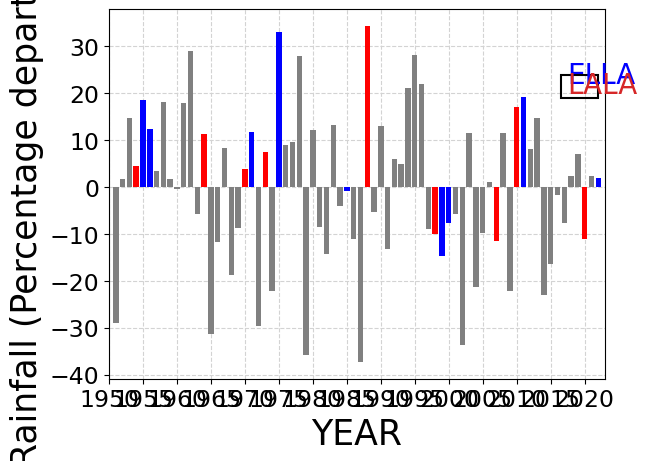

In [15]:
# 'matplotlib.pyplot' will help us here 
ax = plt.gca()
YEAR=np.arange(1951,2023)
ax.grid(which='major', axis='x', linestyle='dashed',color='lightgray')
ax.grid(which='major', axis='y', linestyle='dashed',color='lightgray')
color= ['gray','gray','gray','r','b','b','gray','gray','gray','gray',#-----------1951-1960
        'gray','gray','gray','r','gray','gray','gray','gray','gray','r',#-----------1961-1970
        'b','gray','r','gray','b','gray','gray','gray','gray','gray',#-----------1971-1980
        'gray','gray','gray','gray','b','gray','gray','r','gray','gray',#-----------1981-1990
        'gray','gray','gray','gray','gray','gray','gray','r','b','b',#-----------1991-2000
        'gray','gray','gray','gray','gray','gray','r','gray','gray','r',#-----------2001-2010
        'b','gray','gray','gray','gray','gray','gray','gray','gray','r','gray','b']#--2011-2020       
plt.bar(YEAR, ano_nw, color= color)
ax.xaxis.set_ticks(np.arange(1950, 2023, 5))
ax.set_axisbelow(True)
plt.rcParams["figure.figsize"]=(15,9)
plt.xlim(1950, 2023)
#plt.ylim(-24, 24)
plt.xticks(rotation=0)
plt.xlabel("YEAR", fontsize=25)
plt.text(2017.5,22,'ELLA', fontsize=20, color='blue')
plt.text(2017.5,20, 'LALA', fontsize=20, color='tab:red')
#plt.text(2010,20, 'Neutral', fontsize=15, color='gray')
plt.ylabel("Rainfall (Percentage departure)", fontsize=25)
plt.xticks(fontsize=17)
plt.yticks(fontsize=17)
#plt.title(" India JJAS Percentage rainfall anomaly (1901 to 2020)", fontsize=20)
# specify the location of (left,bottom),width,height
rect=mpatches.Rectangle((2016.5,19),5.5,4.87, 
                        fill = False,
                        color = "k",
                        linewidth = 1.5)
plt.gca().add_patch(rect)
#plt.savefig('JJAS_Per_rainfall_ano_1961_2021ELLA_LALA.jpg',dpi=600)
plt.show()

In [16]:
from shapely.geometry import Polygon, MultiPolygon, Point

In [17]:
# Choose the index of the homogeneous region you want to mask
region_index = 1

# Get the geometry of the selected region
c_geometry = df['geometry'][region_index]

# Create a 2D mask array with NaN values
mask_c = np.full((len(lat), len(lon)), np.nan)

# Check if the region is a MultiPolygon
if isinstance(c_geometry, MultiPolygon):
    # Iterate over each polygon within the MultiPolygon
    for polygon in c_geometry.geoms:
        # Iterate over each grid point
        for i in range(len(lon)):
            for j in range(len(lat)):
                # Check if the grid point falls within the region
                if polygon.contains(Point(lon[i], lat[j])):
                    mask_c[j, i] = 1  # Inside the region
else:
    # Create a shapely Polygon object from the geometry
    polygon = c_geometry
    # Iterate over each grid point
    for i in range(len(lon)):
        for j in range(len(lat)):
            # Check if the grid point falls within the region
            if polygon.contains(Point(lon[i], lat[j])):
                mask_c[j, i] = 1  # Inside the region

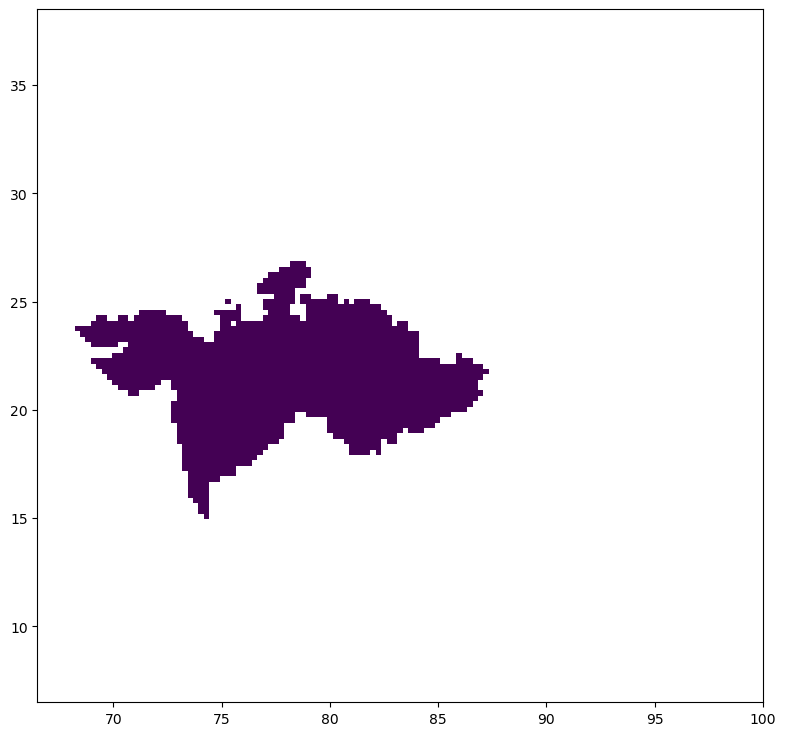

In [18]:
# Plot the mask
plt.imshow(mask_c, extent=[lon.min(), lon.max(), lat.min(), lat.max()], origin='lower')

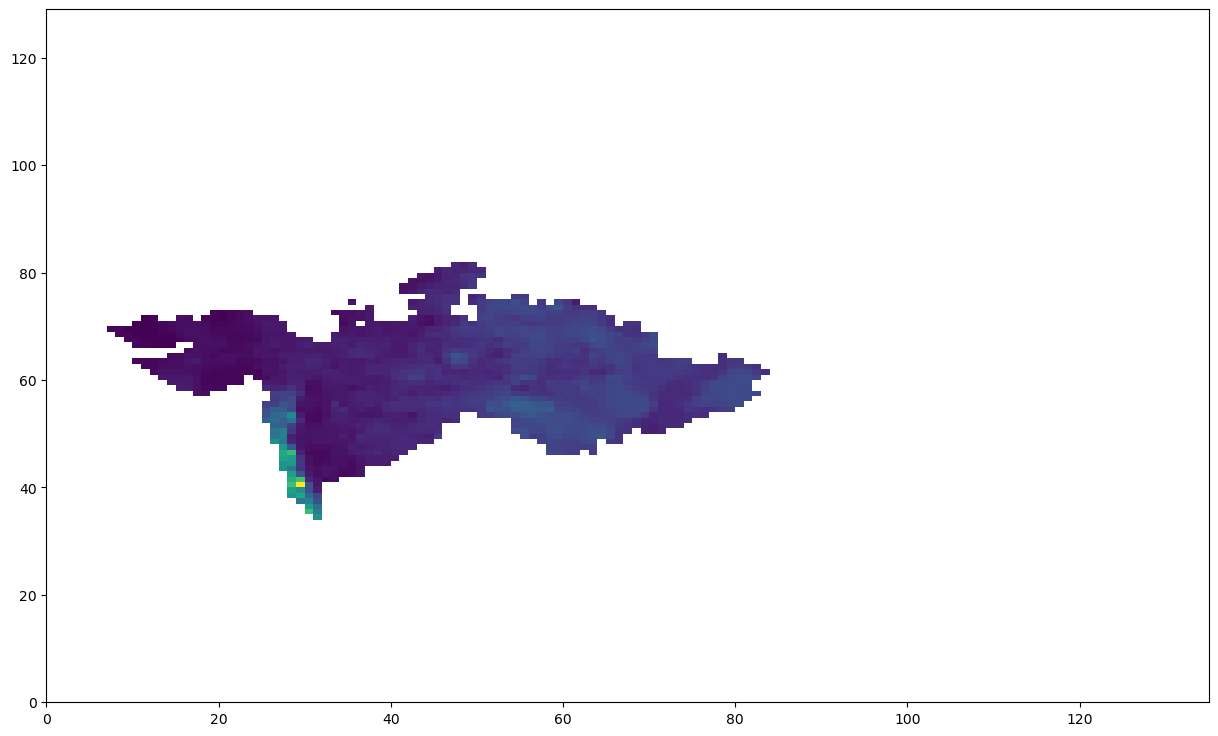

In [19]:
rf_c=r_JJAS*mask_c
plt.pcolormesh(rf_c[0,:,:])

In [20]:
r_c= np.nanmean(rf_c, axis =(1,2))
r_c

array([ 815.05386359,  926.90233305, 1025.53741591, 1054.67325002,
       1070.37188786, 1160.36938653,  886.75695968, 1085.70638495,
       1202.66603226,  938.75821497, 1263.10899087,  923.94453734,
        976.27780448, 1035.50142757,  742.0748623 ,  777.45337515,
       1019.78772392,  833.32118567, 1000.12455192, 1145.0046995 ,
        970.51503976,  760.38760631, 1102.8036912 ,  701.8375992 ,
       1113.1779229 , 1040.84844885, 1029.75806546, 1010.6984466 ,
        802.24130851, 1057.21502224,  981.12502447,  830.17176061,
       1121.16207941,  909.96660944,  840.32937049,  862.31386205,
        713.97879177, 1077.35506434,  945.14335959, 1115.49681517,
        902.96775113,  960.05709592,  980.94623332, 1316.85995788,
        841.69033317,  902.42060098,  995.02133215,  930.12930564,
        957.84578366,  776.05394209,  983.40620222,  794.04424336,
       1098.30843338,  889.09534573, 1121.34608168, 1195.06438722,
       1082.70157235,  968.21024768,  811.65892416, 1011.30819

In [21]:
rclim_c=np.mean(r_c)
rclim_c

981.6317896467049

In [22]:
ano_c=((r_c-rclim_c)/rclim_c)*100
ano_c

array([-16.9694918 ,  -5.57535495,   4.47271846,   7.4408206 ,
         9.04005954,  18.20821196,  -9.66501197,  10.60220303,
        22.51702165,  -4.36758214,  28.67441786,  -5.87666913,
        -0.54541685,   5.4877642 , -24.40394961, -20.79989836,
         3.88699049, -15.10857794,   1.88387973,  16.64299298,
        -1.13247656, -22.53840856,  12.34392598, -28.50296755,
        13.40076133,   6.03247163,   4.90268106,   2.96105498,
       -18.27472205,   7.69975396,  -0.05162477, -15.42941362,
        14.21411687,  -7.30061729, -14.3946458 , -12.15505945,
       -27.2661298 ,   9.75144404,  -3.71711984,  13.63698965,
        -8.01359933,  -2.19783976,  -0.06983844,  34.15009291,
       -14.25600291,  -8.06933817,   1.36400865,  -5.24661941,
        -2.42310877, -20.94246027,   0.18076152, -19.10976685,
        11.88598871,  -9.4267978 ,  14.2328614 ,  21.74263301,
        10.29609919,  -1.36726847, -17.31533833,   3.02317079,
        14.24131938,  -2.63271655,  21.51241501, -10.01

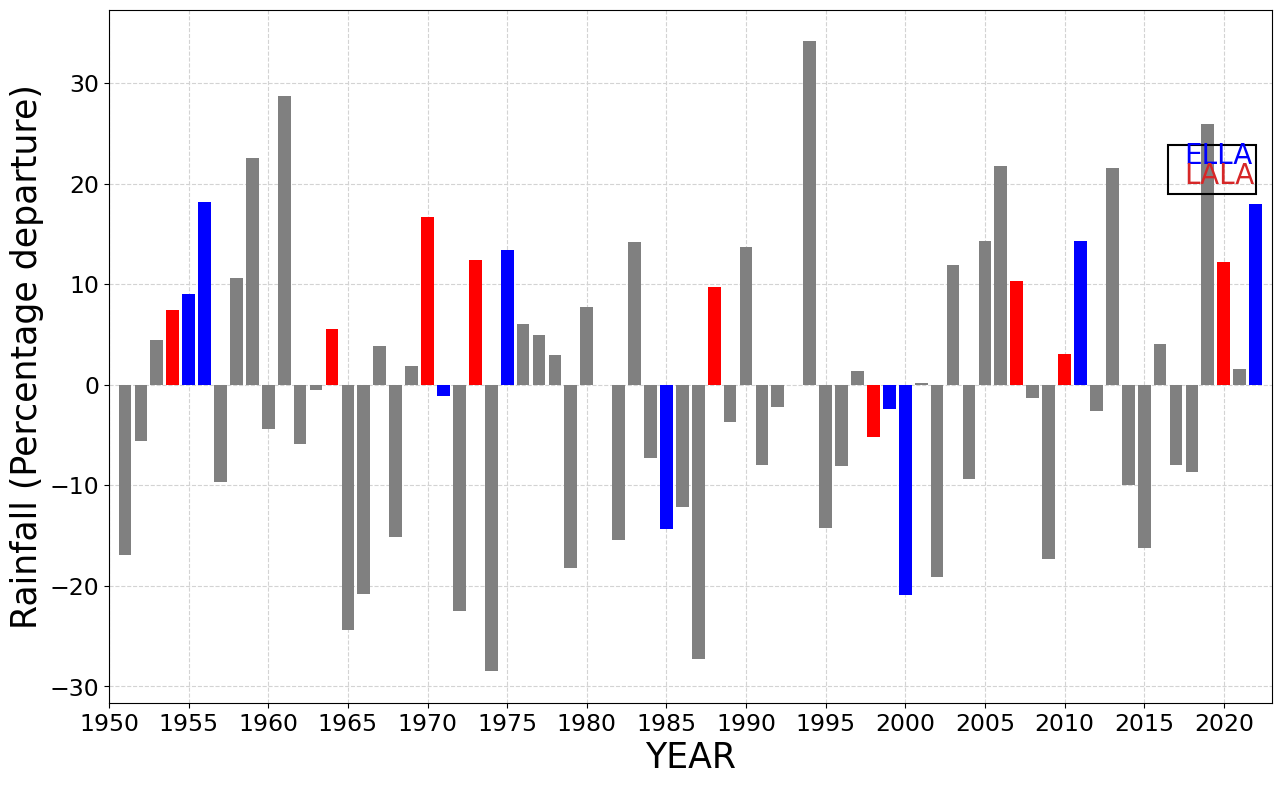

In [23]:
# 'matplotlib.pyplot' will help us here 
ax = plt.gca()
#YEAR=np.arange(1951,2023)
ax.grid(which='major', axis='x', linestyle='dashed',color='lightgray')
ax.grid(which='major', axis='y', linestyle='dashed',color='lightgray')
color= ['gray','gray','gray','r','b','b','gray','gray','gray','gray',#-----------1951-1960
        'gray','gray','gray','r','gray','gray','gray','gray','gray','r',#-----------1961-1970
        'b','gray','r','gray','b','gray','gray','gray','gray','gray',#-----------1971-1980
        'gray','gray','gray','gray','b','gray','gray','r','gray','gray',#-----------1981-1990
        'gray','gray','gray','gray','gray','gray','gray','r','b','b',#-----------1991-2000
        'gray','gray','gray','gray','gray','gray','r','gray','gray','r',#-----------2001-2010
        'b','gray','gray','gray','gray','gray','gray','gray','gray','r','gray','b']#--2011-2020       
plt.bar(YEAR, ano_c, color= color)
ax.xaxis.set_ticks(np.arange(1950, 2023, 5))
ax.set_axisbelow(True)
plt.rcParams["figure.figsize"]=(15,9)
plt.xlim(1950, 2023)
#plt.ylim(-24, 24)
plt.xticks(rotation=0)
plt.xlabel("YEAR", fontsize=25)
plt.text(2017.5,22,'ELLA', fontsize=20, color='blue')
plt.text(2017.5,20, 'LALA', fontsize=20, color='tab:red')
#plt.text(2010,20, 'Neutral', fontsize=15, color='gray')
plt.ylabel("Rainfall (Percentage departure)", fontsize=25)
plt.xticks(fontsize=17)
plt.yticks(fontsize=17)
#plt.title(" India JJAS Percentage rainfall anomaly (1901 to 2020)", fontsize=20)
# specify the location of (left,bottom),width,height
rect=mpatches.Rectangle((2016.5,19),5.5,4.87, 
                        fill = False,
                        color = "k",
                        linewidth = 1.5)
plt.gca().add_patch(rect)
#plt.savefig('JJAS_Per_rainfall_ano_1961_2021ELLA_LALA.jpg',dpi=600)
plt.show()

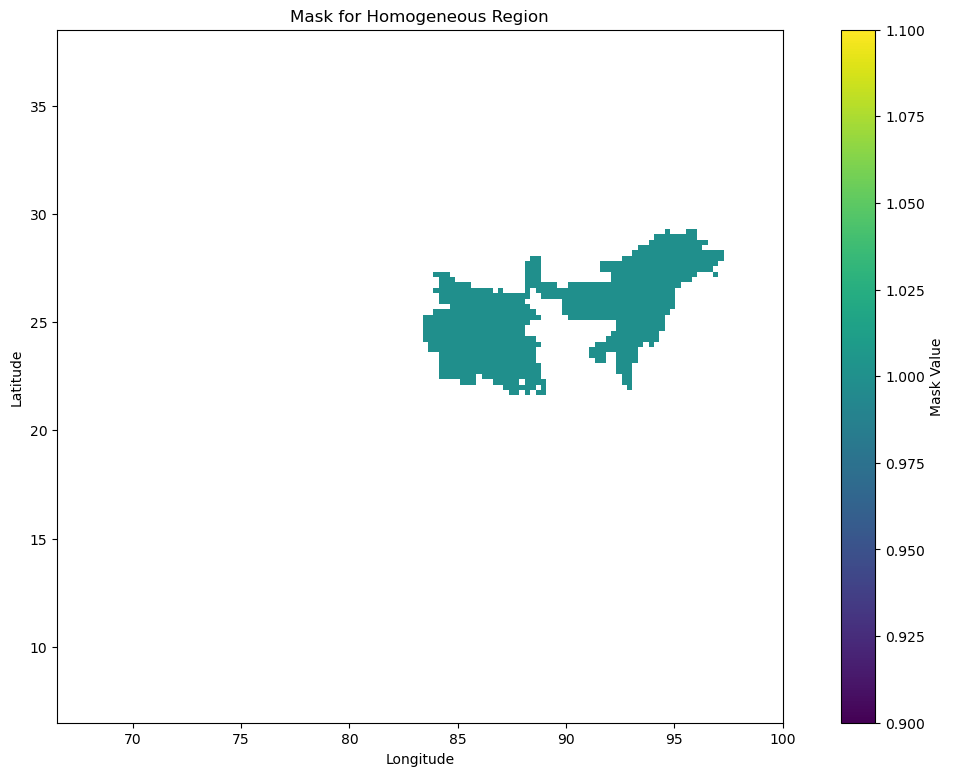

In [24]:
# Choose the index of the homogeneous region you want to mask
ne_index = 2

# Get the geometry of the selected region
ne_geometry = df['geometry'][ne_index]

# Create a 2D mask array with NaN values
mask_ne = np.full((len(lat), len(lon)), np.nan)


# Check if the region is a MultiPolygon
if isinstance(ne_geometry, MultiPolygon):
    # Iterate over each polygon within the MultiPolygon
    for polygon in ne_geometry.geoms:
        # Iterate over each grid point
        for i in range(len(lon)):
            for j in range(len(lat)):
                # Check if the grid point falls within the region
                if polygon.contains(Point(lon[i], lat[j])):
                    mask_ne[j, i] = 1  # Inside the region
else:
    # Create a shapely Polygon object from the geometry
    polygon = ne_geometry
    # Iterate over each grid point
    for i in range(len(lon)):
        for j in range(len(lat)):
            # Check if the grid point falls within the region
            if polygon.contains(Point(lon[i], lat[j])):
                mask_ne[j, i] = 1  # Inside the region

# Plot the mask
plt.imshow(mask_ne, extent=[lon.min(), lon.max(), lat.min(), lat.max()], origin='lower')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Mask for Homogeneous Region')
plt.colorbar(label='Mask Value')
plt.show()

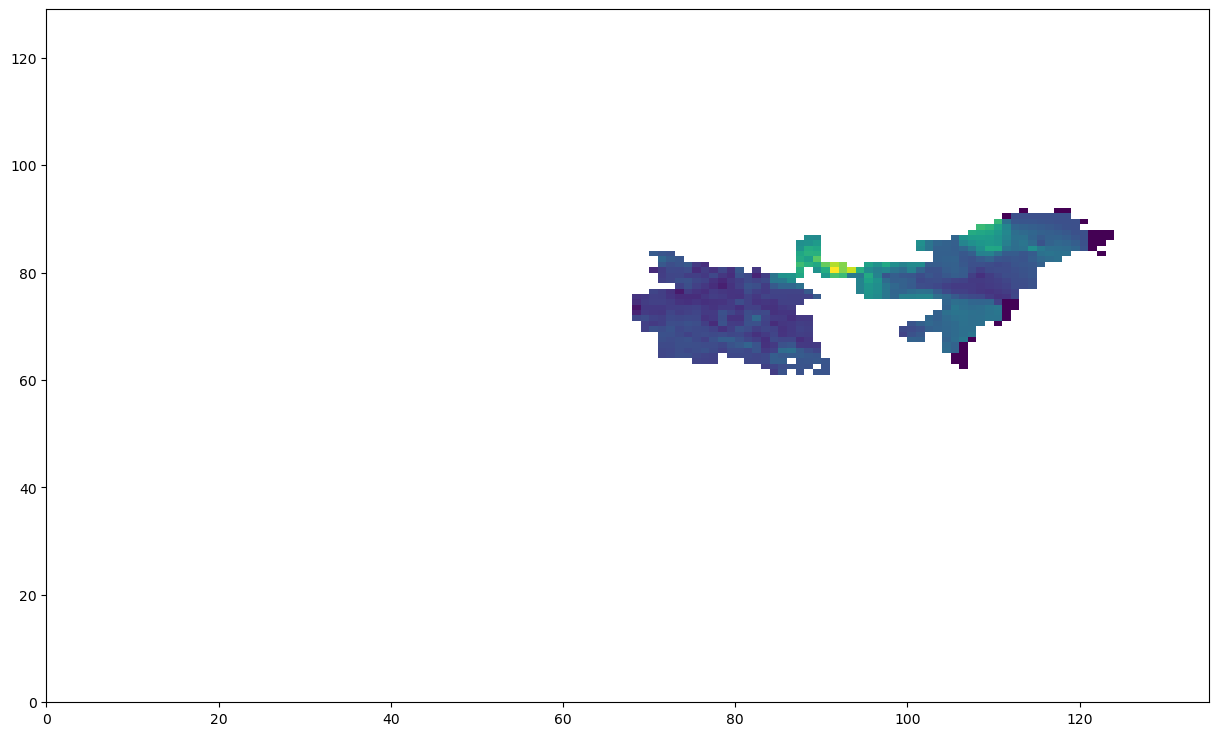

In [25]:
rf_ne=r_JJAS*mask_ne
plt.pcolormesh(rf_ne[0,:,:])

In [26]:
r_ne= np.nanmean(rf_ne, axis =(1,2))
r_ne

array([1158.73349441, 1349.7838141 , 1401.73146893, 1276.14735489,
       1323.22597146, 1301.22083886, 1283.9369614 , 1343.52905149,
       1299.49143189, 1449.95802863, 1237.0106336 , 1108.50802792,
       1370.01270014, 1485.41076667, 1354.06540893, 1347.85572897,
       1229.98932973, 1294.23434519, 1288.30887209, 1509.54478249,
       1584.82743832, 1147.01481479, 1407.80979685, 1834.27435571,
       1394.04024997, 1378.40107683, 1413.41441827, 1300.36601198,
       1196.89476105, 1464.51393173, 1311.96071275, 1287.05456214,
       1349.98833259, 1640.04477184, 1454.26440131, 1289.35258556,
       1756.05914816, 1490.77195128, 1427.23624526, 1475.8416914 ,
       1464.23798658, 1155.91809525, 1502.86475215, 1091.59416421,
       1545.15066928, 1216.06942201, 1420.67007731, 1554.70262285,
       1407.72434136, 1296.89859817, 1225.00904894, 1379.65452767,
       1377.3540547 , 1318.60547769, 1216.56049174, 1148.03201419,
       1529.85236312, 1482.51475272, 1140.22064742, 1327.08295

In [27]:
rclim_ne=np.mean(r_ne)
rclim_ne

1348.987609530628

In [28]:
ano_ne=((r_ne-rclim_ne)/rclim_ne)*100
ano_ne

array([-14.10347388,   0.05902238,   3.90988464,  -5.3996237 ,
        -1.90970161,  -3.54093472,  -4.82218277,  -0.40464108,
        -3.66913508,   7.48490337,  -8.30081575, -17.8266709 ,
         1.55858293,  10.11300298,   0.37641557,  -0.08390593,
        -8.82130265,  -4.05884116,  -4.4980945 ,  11.90204949,
        17.48272757, -14.97217568,   4.36046906,  35.97414407,
         3.33973716,   2.18041049,   4.77593777,  -3.60430275,
       -11.27459195,   8.5639276 ,  -2.74479147,  -4.59107607,
         0.07418327,  21.57597003,   7.80413334,  -4.42072437,
        30.17607692,  10.5104258 ,   5.80054518,   9.40365063,
         8.54347188, -14.31217847,  11.40686108, -19.08048995,
        14.54150197,  -9.85318075,   5.31379735,  15.24958509,
         4.35413427,  -3.86134098,  -9.1904892 ,   2.27332838,
         2.10279509,  -2.25221726,  -9.81677792, -14.89677102,
        13.40744365,   9.89832243, -15.47582503,  -1.6237845 ,
       -13.06957187, -19.91832239, -16.94900653,  -3.64

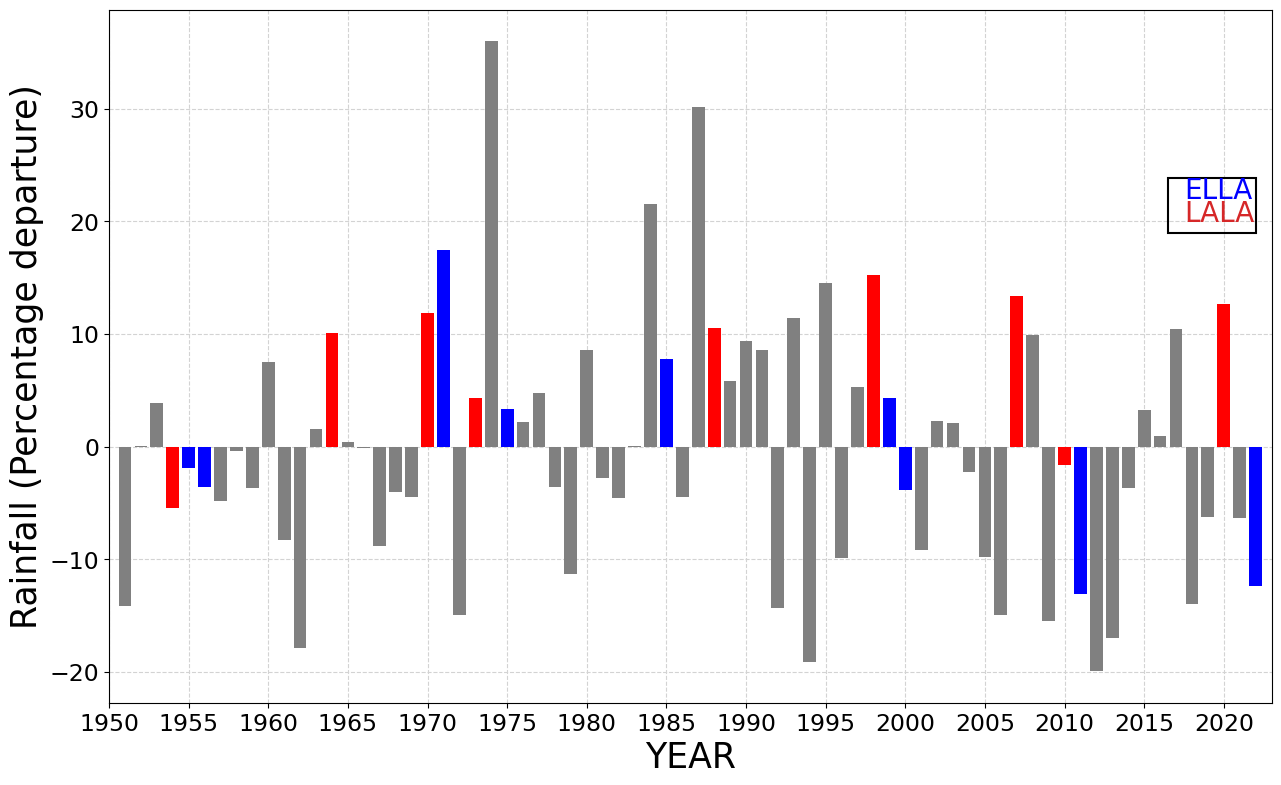

In [29]:
# 'matplotlib.pyplot' will help us here 
ax = plt.gca()
#YEAR=np.arange(1951,2023)
ax.grid(which='major', axis='x', linestyle='dashed',color='lightgray')
ax.grid(which='major', axis='y', linestyle='dashed',color='lightgray')
color= ['gray','gray','gray','r','b','b','gray','gray','gray','gray',#-----------1951-1960
        'gray','gray','gray','r','gray','gray','gray','gray','gray','r',#-----------1961-1970
        'b','gray','r','gray','b','gray','gray','gray','gray','gray',#-----------1971-1980
        'gray','gray','gray','gray','b','gray','gray','r','gray','gray',#-----------1981-1990
        'gray','gray','gray','gray','gray','gray','gray','r','b','b',#-----------1991-2000
        'gray','gray','gray','gray','gray','gray','r','gray','gray','r',#-----------2001-2010
        'b','gray','gray','gray','gray','gray','gray','gray','gray','r','gray','b']#--2011-2020       
plt.bar(YEAR, ano_ne, color= color)
ax.xaxis.set_ticks(np.arange(1950, 2023, 5))
ax.set_axisbelow(True)
plt.rcParams["figure.figsize"]=(15,9)
plt.xlim(1950, 2023)
#plt.ylim(-24, 24)
plt.xticks(rotation=0)
plt.xlabel("YEAR", fontsize=25)
plt.text(2017.5,22,'ELLA', fontsize=20, color='blue')
plt.text(2017.5,20, 'LALA', fontsize=20, color='tab:red')
#plt.text(2010,20, 'Neutral', fontsize=15, color='gray')
plt.ylabel("Rainfall (Percentage departure)", fontsize=25)
plt.xticks(fontsize=17)
plt.yticks(fontsize=17)
#plt.title(" India JJAS Percentage rainfall anomaly (1901 to 2020)", fontsize=20)
# specify the location of (left,bottom),width,height
rect=mpatches.Rectangle((2016.5,19),5.5,4.87, 
                        fill = False,
                        color = "k",
                        linewidth = 1.5)
plt.gca().add_patch(rect)
#plt.savefig('JJAS_Per_rainfall_ano_1961_2021ELLA_LALA.jpg',dpi=600)
plt.show()

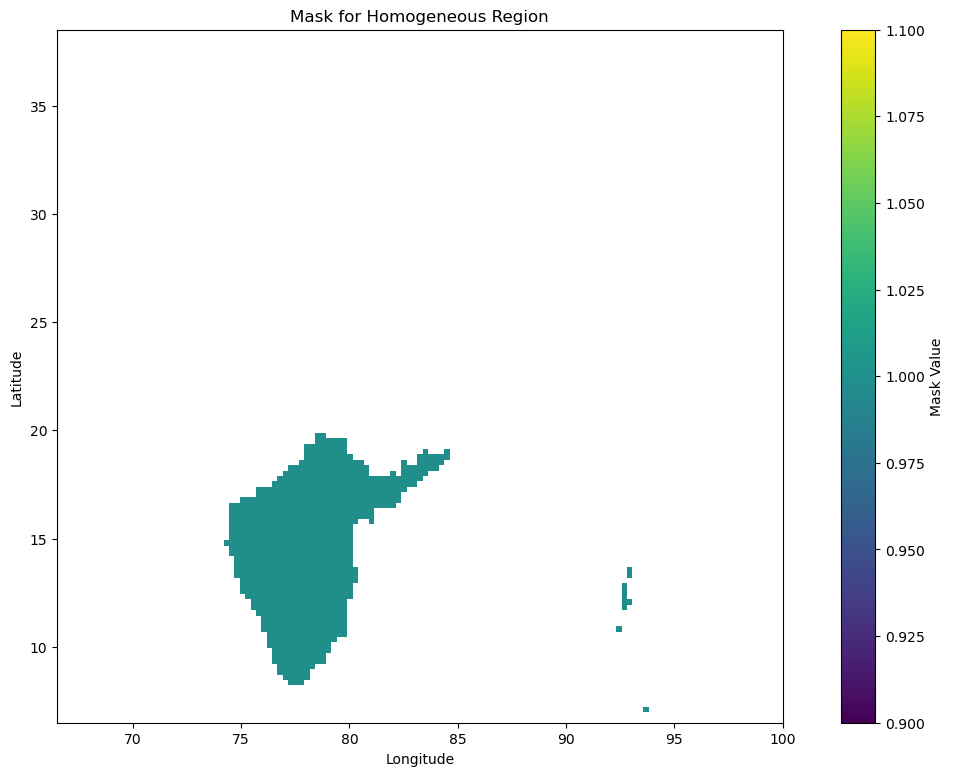

In [30]:
# Choose the index of the homogeneous region you want to mask
sp_index = 3

# Get the geometry of the selected region
sp_geometry = df['geometry'][sp_index]

# Create a 2D mask array with NaN values
mask_sp = np.full((len(lat), len(lon)), np.nan)


# Check if the region is a MultiPolygon
if isinstance(sp_geometry, MultiPolygon):
    # Iterate over each polygon within the MultiPolygon
    for polygon in sp_geometry.geoms:
        # Iterate over each grid point
        for i in range(len(lon)):
            for j in range(len(lat)):
                # Check if the grid point falls within the region
                if polygon.contains(Point(lon[i], lat[j])):
                    mask_sp[j, i] = 1  # Inside the region
else:
    # Create a shapely Polygon object from the geometry
    polygon = sp_geometry
    # Iterate over each grid point
    for i in range(len(lon)):
        for j in range(len(lat)):
            # Check if the grid point falls within the region
            if polygon.contains(Point(lon[i], lat[j])):
                mask_sp[j, i] = 1  # Inside the region

# Plot the mask
plt.imshow(mask_sp, extent=[lon.min(), lon.max(), lat.min(), lat.max()], origin='lower')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Mask for Homogeneous Region')
plt.colorbar(label='Mask Value')
plt.show()

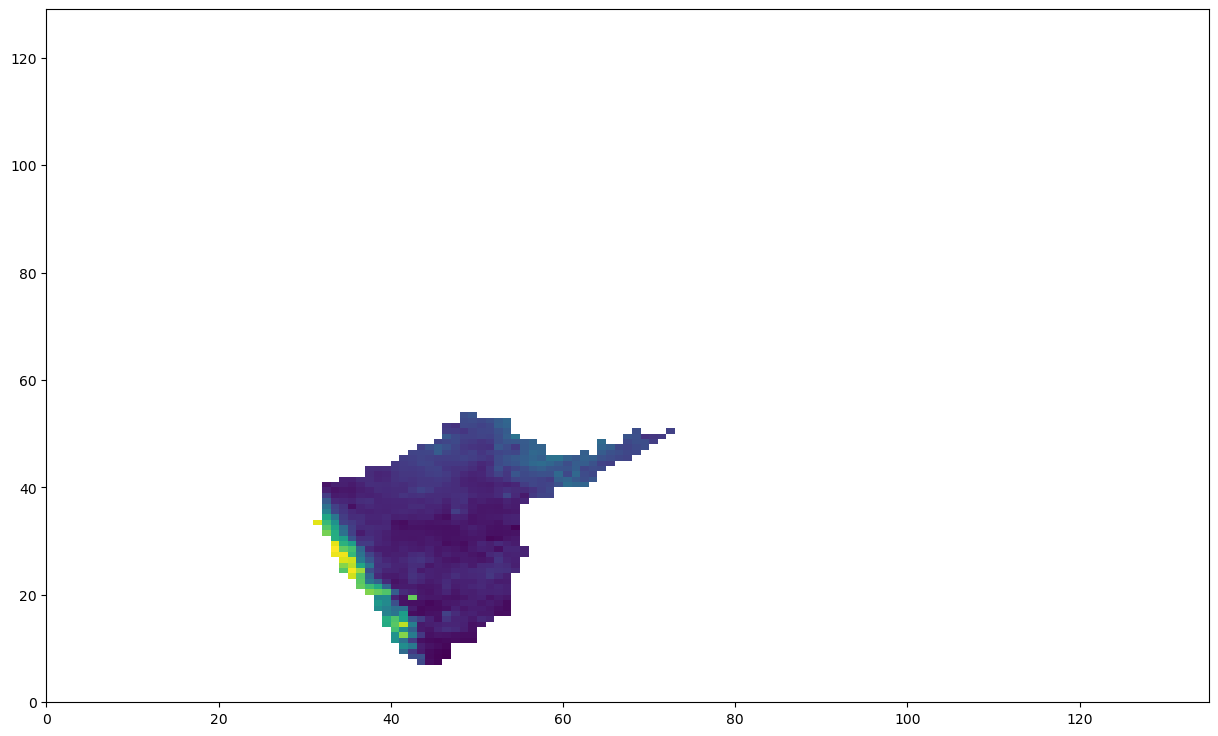

In [31]:
rf_sp=r_JJAS*mask_sp
plt.pcolormesh(rf_sp[0,:,:])

In [32]:
r_sp= np.nanmean(rf_sp, axis =(1,2))
r_sp

array([621.7106522 , 465.53293365, 744.15636107, 709.12964902,
       689.74204687, 755.74180452, 659.00854796, 728.12633254,
       858.56119534, 661.5084576 , 819.08616078, 749.30489836,
       624.70648589, 802.03919802, 611.29825546, 644.92481805,
       643.20398572, 602.56901555, 632.10545228, 690.67279822,
       581.59874861, 506.86503322, 643.07828304, 637.22200309,
       824.6264494 , 602.12409537, 592.5424797 , 781.04609721,
       628.68584078, 672.93753742, 819.32044339, 605.13670051,
       862.02699444, 619.8153522 , 575.32865051, 601.42567225,
       505.40631274, 849.96177998, 764.33118866, 629.5856981 ,
       726.17911342, 662.81935905, 571.11817715, 612.40403807,
       646.01377751, 750.32232399, 628.78303949, 772.21328246,
       558.47463887, 752.76833863, 551.50714819, 416.54581772,
       531.70483273, 566.27776163, 722.63651984, 632.78075973,
       834.52735145, 685.83697352, 633.2420564 , 806.79075774,
       786.2578658 , 766.27221244, 766.88036191, 627.03

In [33]:
rclim_sp=np.mean(r_sp)
rclim_sp

679.1190621887998

In [34]:
ano_sp=((r_sp-rclim_sp)/rclim_sp)*100
print(ano_sp.shape)

(72,)


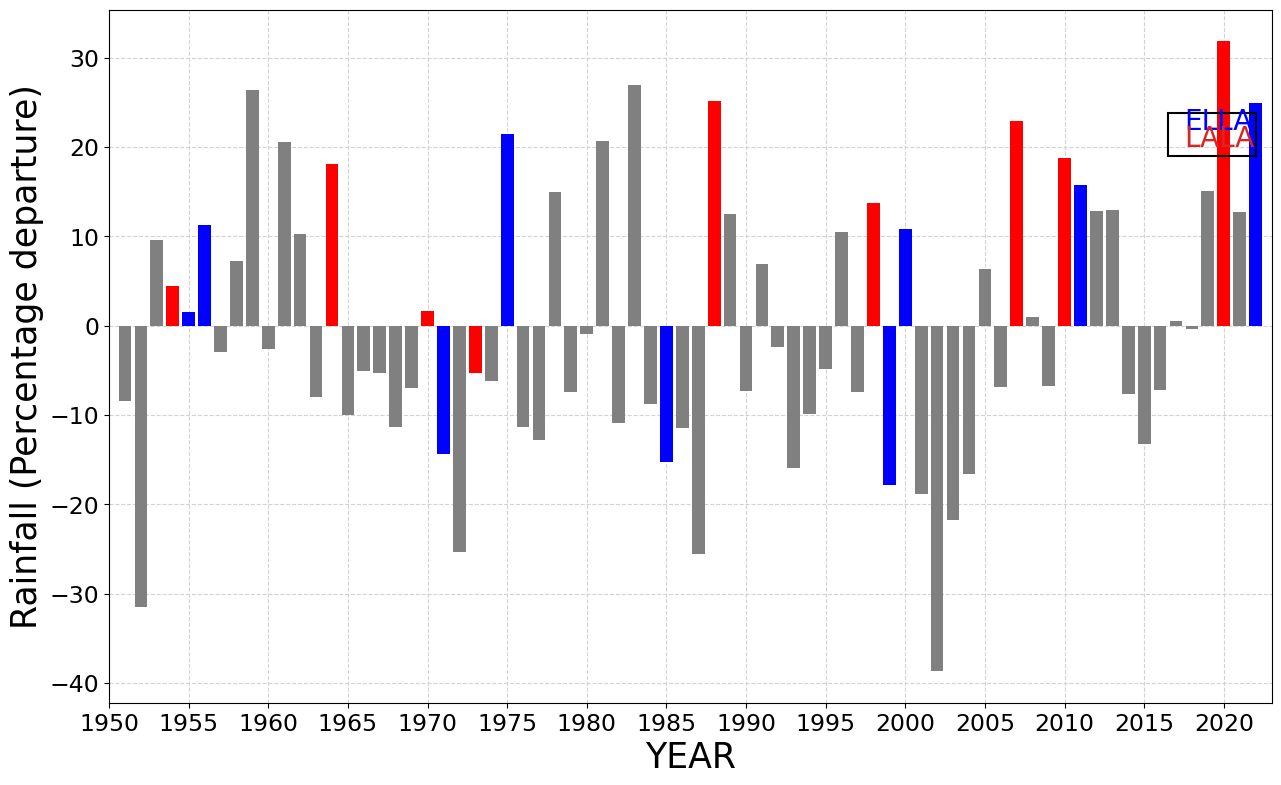

In [35]:
# 'matplotlib.pyplot' will help us here 
ax = plt.gca()
#YEAR=np.arange(1951,2023)
ax.grid(which='major', axis='x', linestyle='dashed',color='lightgray')
ax.grid(which='major', axis='y', linestyle='dashed',color='lightgray')
color= ['gray','gray','gray','r','b','b','gray','gray','gray','gray',#-----------1951-1960
        'gray','gray','gray','r','gray','gray','gray','gray','gray','r',#-----------1961-1970
        'b','gray','r','gray','b','gray','gray','gray','gray','gray',#-----------1971-1980
        'gray','gray','gray','gray','b','gray','gray','r','gray','gray',#-----------1981-1990
        'gray','gray','gray','gray','gray','gray','gray','r','b','b',#-----------1991-2000
        'gray','gray','gray','gray','gray','gray','r','gray','gray','r',#-----------2001-2010
        'b','gray','gray','gray','gray','gray','gray','gray','gray','r','gray','b']#--2011-2020       
plt.bar(YEAR, ano_sp, color= color)
ax.xaxis.set_ticks(np.arange(1950, 2023, 5))
ax.set_axisbelow(True)
plt.rcParams["figure.figsize"]=(15,9)
plt.xlim(1950, 2023)
#plt.ylim(-24, 24)
plt.xticks(rotation=0)
plt.xlabel("YEAR", fontsize=25)
plt.text(2017.5,22,'ELLA', fontsize=20, color='blue')
plt.text(2017.5,20, 'LALA', fontsize=20, color='tab:red')
#plt.text(2010,20, 'Neutral', fontsize=15, color='gray')
plt.ylabel("Rainfall (Percentage departure)", fontsize=25)
plt.xticks(fontsize=17)
plt.yticks(fontsize=17)
#plt.title(" India JJAS Percentage rainfall anomaly (1901 to 2020)", fontsize=20)
# specify the location of (left,bottom),width,height
rect=mpatches.Rectangle((2016.5,19),5.5,4.87, 
                        fill = False,
                        color = "k",
                        linewidth = 1.5)
plt.gca().add_patch(rect)
#plt.savefig('JJAS_Per_rainfall_ano_1961_2021ELLA_LALA.jpg',dpi=600)
plt.show()

In [36]:
E_t=stats.ttest_ind(ano_nw[[3,13,19,22,37,47,56,59,69]], ano_nw,axis=0,equal_var=True,nan_policy='propagate')
E_t

Ttest_indResult(statistic=0.8573424462055607, pvalue=0.39384908966649346)

In [37]:
E_t2=stats.ttest_ind(ano_nw[[4,5,20,24,34,48,49,60,71]], ano_nw,axis=0,equal_var=True,nan_policy='propagate')
E_t2

Ttest_indResult(statistic=1.3834657079033852, pvalue=0.1704191532035384)

In [38]:
ELLA=ano_nw[[3,13,19,22,37,47,56,59,69]]
ELLA

array([  4.40666852,  11.34877052,   3.87417685,   7.3883341 ,
        34.29598555, -10.12788349, -11.52007185,  16.96758633,
       -11.03846791])

In [39]:
E_t3=stats.ttest_ind(ano_c[[3,13,19,22,37,47,56,59,69]], ano_c,axis=0,equal_var=True,nan_policy='propagate')
E_t3

Ttest_indResult(statistic=1.6785089590038194, pvalue=0.09719951572111515)

In [40]:
E_t4=stats.ttest_ind(ano_c[[4,5,20,24,34,48,49,60,71]], ano_c,axis=0,equal_var=True,nan_policy='propagate')
E_t4

Ttest_indResult(statistic=0.7594089933498684, pvalue=0.44986805926375706)

In [41]:
E_t5=stats.ttest_ind(ano_ne[[3,13,19,22,37,47,56,59,69]], ano_ne,axis=0,equal_var=True,nan_policy='propagate')
E_t5

Ttest_indResult(statistic=2.070718160581019, pvalue=0.041651078615808815)

In [42]:
E_t6=stats.ttest_ind(ano_ne[[4,5,20,24,34,48,49,60,71]], ano_ne,axis=0,equal_var=True,nan_policy='propagate')
E_t6

Ttest_indResult(statistic=-0.04907743545046313, pvalue=0.9609814530122639)

In [43]:
E_t7=stats.ttest_ind(ano_sp[[3,13,19,22,37,47,56,59,69]], ano_sp,axis=0,equal_var=True,nan_policy='propagate')
E_t7

Ttest_indResult(statistic=2.783436743872246, pvalue=0.006726820387373574)

In [44]:
E_t8=stats.ttest_ind(ano_sp[[4,5,20,24,34,48,49,60,71]], ano_sp,axis=0,equal_var=True,nan_policy='propagate')
E_t8

Ttest_indResult(statistic=0.7927457765142507, pvalue=0.4303002765233216)

In [45]:
JJAS_ind=np.nanmean(r_JJAS,axis=(1,2))
JJAS_ind

array([ 709.90141094,  799.62749206,  913.84787035,  887.134755  ,
        913.36159016,  934.82748551,  814.74338319,  928.12597883,
        957.37994101,  852.25261967,  989.01783976,  854.45633045,
        834.03113147,  935.97152881,  711.55913828,  758.37444066,
        854.24422359,  754.35602198,  823.99313716,  949.25341267,
        886.67809335,  661.3022558 ,  904.05201747,  804.68971029,
        994.82902937,  886.94916004,  885.14704791,  922.30916077,
        709.39325302,  920.51033631,  863.57105464,  760.28891314,
        963.3742089 ,  863.58153385,  806.40621839,  769.90740316,
        743.82774125, 1008.34305003,  864.36438559,  931.19335944,
        834.96055997,  825.25865821,  872.29409606,  945.22470452,
        888.76699877,  852.59031265,  848.35484004,  878.20675485,
        803.41410867,  783.60221579,  799.31184177,  693.951597  ,
        894.26077851,  762.10118777,  866.42980449,  882.92891741,
        933.81512556,  890.28381573,  725.10261275,  921.68403

In [46]:
clim_ind=np.mean(JJAS_ind)
clim_ind

856.1576555689303

In [47]:
ano_ind=((JJAS_ind-clim_ind)/clim_ind)*100
ano_ind

array([-17.08286361,  -6.60277498,   6.73827004,   3.61815365,
         6.68147207,   9.18870834,  -4.83722503,   8.40596621,
        11.82285585,  -0.45611178,  15.51819146,  -0.19871633,
        -2.58439832,   9.32233365, -16.88923954, -11.42116925,
        -0.22349061, -11.89052424,  -3.75684527,  10.87366988,
         3.56481515, -22.75928954,   5.59410543,  -6.01150325,
        16.19694374,   3.59647598,   3.38598763,   7.72655653,
       -17.14221693,   7.51645218,   0.86589182, -11.19755711,
        12.52299184,   0.8671158 ,  -5.81101353, -10.07410865,
       -13.1202371 ,  17.77539376,   0.9585536 ,   8.76423908,
        -2.47584022,  -3.60903125,   1.88475106,  10.40311307,
         3.80880122,  -0.41666893,  -0.91137602,   2.57535503,
        -6.16049469,  -8.47454196,  -6.63964323, -18.94581652,
         4.45047973, -10.98588177,   1.19979642,   3.12690796,
         9.07046377,   3.98596683, -15.30734929,   7.65354147,
         7.51519047,  -2.92912994,   8.1634284 , -10.41

In [48]:
E_t9=stats.ttest_ind(ano_ind[[3,13,19,22,37,47,56,59,69]], ano_ind,axis=0,equal_var=True,nan_policy='propagate')
E_t9

Ttest_indResult(statistic=2.778278880914902, pvalue=0.006824704719196358)

In [49]:
E_t10=stats.ttest_ind(ano_ind[[4,5,20,24,34,48,49,60,71]], ano_ind,axis=0,equal_var=True,nan_policy='propagate')
E_t10

Ttest_indResult(statistic=1.0384123450671485, pvalue=0.3022460070797881)

In [54]:
#ELLA
AI=np.array([3.61,9.32,10.87,5.59,17.77,2.57,9.07,7.65,11.77])
NW=np.array([4.42,11.33,3.82,7.37,34.21,-10.13,-11.57,16.88,-10.99])
NE=np.array([-5.39,10.11,11.90,4.36,10.51,15.24,13.40,-1.62,12.63])
CI=np.array([7.44,5.48,16.64,12.34,9.75,-5.24,10.29,3.02,12.15])
PI=np.array([4.41,18.09,1.70,-5.30,25.15,13.70,22.88,18.79,31.85])
print(AI.mean())
print(NW.mean())
print(NE.mean())
print(CI.mean())
print(PI.mean())

8.69111111111111
5.0377777777777775
7.904444444444445
7.985555555555556
14.585555555555553


In [55]:
AI2=ano_ind[[3,13,19,22,37,47,56,59,69]]
NW2=ano_nw[[3,13,19,22,37,47,56,59,69]]
NE2=ano_ne[[3,13,19,22,37,47,56,59,69]]
CI2=ano_c[[3,13,19,22,37,47,56,59,69]]
PI2=ano_sp[[3,13,19,22,37,47,56,59,69]]
AI2
print(AI2.mean())
print(NW2.mean())
print(NE2.mean())
print(CI2.mean())
print(PI2.mean())

8.695144662247014
5.0661220690097535
7.906527772551341
7.9883140752378115
14.591234438720177


In [56]:
#LALA
ai=np.array([6.68,9.18,3.56,16.19,-5.81,-6.16,-8.47,7.51,7.44])
nw=np.array([18.51,12.33,11.65,33.07,-0.85,-14.57,-7.67,19.08,1.96])
ne=np.array([-1.90,-3.45,17.48,3.33,7.80,4.35,-3.86,-13.06,-12.31])
ci=np.array([9.04,18.20,-1.13,13.40,-14.39,-2.42,-20.94,14.24,17.99])
pi=np.array([1.56,11.28,-14.35,21.42,-15.28,-17.76,10.84,15.77,24.94])
print(ai.mean())
print(nw.mean())
print(ne.mean())
print(ci.mean())
print(pi.mean())

3.3466666666666667
8.167777777777777
-0.1800000000000001
3.776666666666666
4.268888888888889


In [58]:
ai2=ano_ind[[4,5,20,24,34,48,49,60,71]]
nw2=ano_nw[[4,5,20,24,34,48,49,60,71]]
ne2=ano_ne[[4,5,20,24,34,48,49,60,71]]
ci2=ano_c[[4,5,20,24,34,48,49,60,71]]
pi2=ano_sp[[4,5,20,24,34,48,49,60,71]]
print(ai2.mean())
print(nw2.mean())
print(ne2.mean())
print(ci2.mean())
print(pi2.mean())

3.350077590027692
8.167772896693156
-0.19076908177299026
3.7768764240754575
4.273084892161725


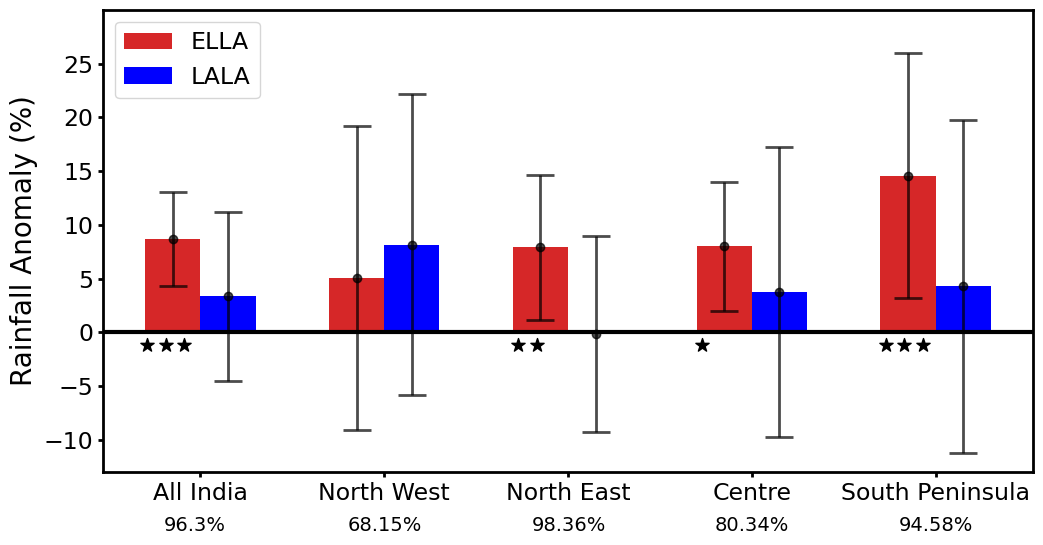

In [96]:
team = ['All India','North West','North East','Centre','South Peninsula']
ELLA = [8.69, 5.03, 7.9, 7.98, 14.58]
LALA = [3.34, 8.16, -0.18, 3.77, 4.27]

ELLA_std = [4.36, 14.14, 6.78, 6.01, 11.42]
LALA_std = [7.87, 13.99, 9.12, 13.51, 15.51]


x_axis = np.arange(len(team))
ax = plt.gca()
# Multiple colors of bars
plt.rcParams["figure.figsize"]=(12,6)
plt.bar(x_axis -0.15, ELLA, width=0.3, 
        label = 'ELLA', color='tab:red')

plt.bar(x_axis +0.15, LALA, width=0.3, 
        label = 'LALA', color='blue')

#plt.errorbar(x_axis -0.15,ELLA, yerr=ELLA_std, xerr=None, fmt='', ecolor='k', 
 #            elinewidth=2, capsize=0.1, barsabove=False, lolims=False, 
  #           uplims=False, xlolims=False, xuplims=False, errorevery=1, 
   #          capthick=None, data=None)
plt.errorbar(x_axis-0.15,ELLA,yerr=ELLA_std,fmt="o",color="k",
             elinewidth=2,capsize=10,capthick=2,alpha=0.7)

plt.errorbar(x_axis+0.15,LALA,yerr=LALA_std,fmt="o",color="k",
             elinewidth=2,capsize=10,capthick=2,alpha=0.7)
# Xticks

plt.xticks(x_axis, team)
plt.ylim(-13, 30)
plt.xticks(fontsize=17)
plt.yticks(fontsize=17)
ax.set_yticks([-10,-5,0,5,10,15,20,25])
ax.xaxis.set_tick_params(width=2)
ax.yaxis.set_tick_params(width=2)
plt.setp(ax.spines.values(), linewidth=2)
plt.axhline(y=0, color='k', linestyle='-', linewidth=3,alpha=1)

# Add legend
plt.axhline(y=0, color='k', linestyle='-',alpha=1)
plt.ylabel("Rainfall Anomaly (%)", fontsize=20)
plt.legend(fontsize=17)
plt.text(-0.2,-18.5,'96.3%',fontsize=14)
plt.text(0.8,-18.5,'68.15%',fontsize=14)
plt.text(1.8,-18.5,'98.36%',fontsize=14)
plt.text(2.8,-18.5,'80.34%',fontsize=14)
plt.text(3.8,-18.5,'94.58%',fontsize=14)
# Add significance stars


plt.scatter(-0.29,-1.15, marker='*', color='black', s=100)
plt.scatter(-0.19,-1.15, marker='*', color='black', s=100)
plt.scatter(-0.09,-1.15, marker='*', color='black', s=100)

plt.scatter(1.73,-1.15, marker='*', color='black', s=100)
plt.scatter(1.83,-1.15, marker='*', color='black', s=100)

plt.scatter(2.73,-1.15, marker='*', color='black', s=100)

plt.scatter(3.73,-1.15, marker='*', color='black', s=100)
plt.scatter(3.83,-1.15, marker='*', color='black', s=100)
plt.scatter(3.93,-1.15, marker='*', color='black', s=100)
# plt.text(-0.29,8.95,'8.69',fontsize=16, color='tab:red')#,weight="bold"
# plt.text(0.02,3.65,'3.34',fontsize=16,color='b')
# plt.text(0.73,5.33,'5.03',fontsize=16, color='tab:red')
# plt.text(1.03,8.46,'8.16',fontsize=16,color='b')
# plt.text(1.75,8.2,'7.9',fontsize=16, color='tab:red')
# plt.text(1.99,-1.74,'-0.18',fontsize=16,color='b')
# plt.text(2.72,8.28,'7.98',fontsize=16, color='tab:red')
# plt.text(3.02,4.07,'3.77',fontsize=16,color='b')
# plt.text(3.68,14.88,'14.58',fontsize=16, color='tab:red')
# plt.text(4.02,4.57,'4.27',fontsize=16,color='b')

# Display
#plt.savefig('ELLA_LALArf_ano1951_2022.jpg',dpi=600)
#plt.savefig('ELLA_LALArf_ano1951_2022_SigDiff_ErrorBar_revised.jpg',dpi=600)
plt.show()